# Simulate the TOA signal from user settings

This first tutorial simulates the top-of-atmosphere (TOA) signal above a water body for settings chosen
by the user: geometry, atmosphere, sea-surface roughness and water reflectance. It runs the processing
chain of {py:class}`~radcalnet_oc.process.Process` with the options of version 1.1, adds the direct
sunglint, and shows how each setting changes the signal.

The TOA reflectance (Eq. {eq}`rtoa_rrs` of the {doc}`../methods` page) is

$$
R_{toa}(\lambda) = \pi\, R_{rs}(\lambda)\, T^{\downarrow}(\lambda)\, t^{\uparrow}(\lambda)\, T_g^{w}(\lambda)
+ T_g^{atm}(\lambda)\, R_{atm}(\lambda)
+ T_{dir}(\lambda)\, R_{sg},
$$

with three terms:

- **water**: the remote-sensing reflectance $R_{rs}$ transmitted through the atmosphere (diffuse
  transmittances $T^{\downarrow}$, $t^{\uparrow}$);
- **atmosphere**: the path reflectance $R_{atm}$ of the look-up tables (Rayleigh and aerosol
  scattering, skylight reflected by the rough sea surface);
- **sunglint**: the direct sunlight reflected by the wave facets, $R_{sg}$ (Cox and Munk), attenuated by
  the direct transmittance $T_{dir}$. It is not in the look-up tables nor in `Process`: it is computed
  here with {py:class}`~radcalnet_oc.coxmunk.Sunglint` and added.

Each term has its own gaseous transmittance $T_g^{X}$, from the photon path-length model of the
absorption coupled with the scattering (option `gas_coupling`, {ref}`methods-gas-coupling`).

| Setting | Variable or option | Unit |
|---|---|---|
| Geometry | `sza` (input), `vza`, `azi` (arguments of `Process`), `day_of_year` (input) | deg, - |
| Atmosphere | `aot550`, `pressure`, `tcwv`, `tco3`, `tcno2` (input); `aerosol_combination` (`execute`) | -, hPa, kg m$^{-2}$ |
| Sea surface | `wind` (input): roughness of the sky reflection and of the sunglint; wind direction and slope statistics of the sunglint | m s$^{-1}$, deg |
| Water | `Rrs` (input, dimensions `time`, `wl`) | sr$^{-1}$ |
| Options | `gas_coupling`, `o2_model`, `rrs_extension`, `solar_database` (arguments of `Process`) | |

The azimuth `azi` follows the convention of the look-up tables: 0° when the sensor looks towards the Sun
(sunglint side), 180° in the backscattering direction.

In [1]:
import logging
from importlib.resources import files

import matplotlib as mpl
import matplotlib.pyplot as plt
rc = {"font.family": "serif",
      "mathtext.fontset": "stix"}
plt.rcParams.update(rc)
plt.rcParams["font.serif"] = ["Times New Roman"] + plt.rcParams["font.serif"]
plt.rcParams.update({'font.size': 16, 'axes.labelsize': 18})
# no warning when the Times New Roman font is not installed
logging.getLogger('matplotlib.font_manager').setLevel(logging.ERROR)

import numpy as np
import pandas as pd
import xarray as xr

import radcalnet_oc as radoc
# radcalnet_oc sets the root logger to INFO: show only the warnings in this tutorial
logging.getLogger().setLevel(logging.WARNING)
print(f'radcalnet_oc: {radoc.__version__}')

radcalnet_oc: 1.1.0


## User settings

All the settings of the simulation are gathered here. The gas columns are converted into the units of
the input (kg m$^{-2}$): 1 cm of precipitable water is 10 kg m$^{-2}$ and 1 Dobson unit of ozone is
2.1415$\times10^{-5}$ kg m$^{-2}$.

The water reflectance is one of the spectra shipped with the package (`template_clear_water.nc`,
`template_turbid_water.nc`, 350-1150 nm), or any $R_{rs}$ spectrum of the user as an
{py:class}`xarray.DataArray` with a `wl` dimension (nm). Beyond its spectral range, $R_{rs}$ is extended
up to 2500 nm (option `rrs_extension`, {ref}`methods-rrs`).

In [2]:
DU = 2.1415e-5  # kg m-2 per Dobson unit of ozone

settings = dict(
    # geometry
    sza=40.,            # solar zenith angle (deg)
    vza=10.,            # viewing zenith angle (deg)
    azi=90.,            # relative azimuth (deg), 0: towards the Sun (sunglint side)
    day_of_year=172,    # Earth-Sun distance
    # atmosphere
    aot550=0.1,         # aerosol optical thickness at 550 nm
    aot865=0.06,        # copied to the output only
    ang_exp=1.2,        # copied to the output only
    aerosol_combination=[0, 0.5, 0, 0.5, 0, 0],  # proportions of the aerosol models (config.yml)
    pressure=1013.25,   # surface pressure (hPa)
    tcwv=2.0 * 10,      # water vapour: 2 cm -> kg m-2
    tco3=300 * DU,      # ozone: 300 DU -> kg m-2
    tcno2=2e-5,         # nitrogen dioxide (kg m-2)
    # sea surface
    wind=5.,            # wind speed at 10 m (m s-1)
    wind_azi=0.,        # wind direction relative to the solar azimuth (deg), sunglint only
    glint_stats='cm_iso',  # slope statistics of the sunglint: 'cm_iso', 'cm_dir', 'bh2006'
    # water
    water='clear',      # 'clear', 'turbid', 'black' or an Rrs DataArray (dimension wl, sr-1)
)

# options of the simulation (defaults of version 1.1 in config.yml)
options = dict(gas_coupling='path_length',  # 'path_length', 'effective_air_mass', 'decoupled'
               o2_model='lbl',              # 'lbl' (line by line) or 'reptran'
               rrs_extension='pure_water',  # 'pure_water' or 'zero'
               solar_database='tsis')       # 'tsis', 'thuillier', 'gueymard', 'kurucz'

print('aerosol models:', radoc.process.AEROSOL_MODELS)

aerosol models: ['ARCT_rh70', 'COAV_rh70', 'DESE_rh70', 'MACL_rh70', 'URBA_rh70', 'WASO_rh0']


## From the settings to the simulation

Three helper functions:

- `make_input` builds the input dataset of {py:class}`~radcalnet_oc.process.Process` (see
  {doc}`../usage`). Each setting can be a list of values: the values are laid along the `time` dimension,
  one scenario per value, so that a whole sensitivity study is computed in a single run;
- `sunglint_toa` computes the direct sunglint at the TOA, $T_{dir}\, R_{sg}$, with
  $T_{dir} = T_g(\lambda, m) \exp[-(\tau_r + \tau_a)\, m]$ and $m = 1/\mu_0 + 1/\mu_v$
  (Eq. {eq}`tdir`), as in the Sentinel-2 matchup script;
- `simulate` runs `Process` and adds the sunglint: the output `Rtoa` is the TOA reflectance without
  sunglint (as given by `Process`), `Rsg_toa` the sunglint term and `Rtoa_sg` their sum.

The simulation is computed at the 0.1 nm resolution of the gaseous absorption table. For readability,
most figures show the spectra convolved with Gaussian responses of 3 nm FWHM every 1 nm (`smooth`), as
measured by a typical field or airborne spectrometer.

In [3]:
TEMPLATES = {'clear': 'template_clear_water.nc', 'turbid': 'template_turbid_water.nc'}
SCALARS = ['sza', 'day_of_year', 'aot550', 'aot865', 'ang_exp', 'pressure', 'tcwv', 'tco3', 'tcno2', 'wind']


def water_rrs(water):
    '''Remote-sensing reflectance (dimension wl) of a template, of black water, or given by the user.'''
    if isinstance(water, xr.DataArray):
        return water
    if water == 'black':
        return xr.DataArray(np.zeros(2), coords={'wl': [350., 1150.]}, dims='wl')
    with xr.open_dataset(files('radcalnet_oc.data.template') / TEMPLATES[water]) as ds:
        return ds.Rrs.isel(time=0, drop=True).load()


def make_input(settings, **sweep):
    '''
    Input dataset of Process: the settings, with the values of ``sweep`` (lists of the same length)
    laid along the time dimension (one scenario per value).
    '''
    s = {**settings, **sweep}
    n = max([len(v) for v in sweep.values()], default=1)
    ds = xr.Dataset(coords={'time': pd.date_range('2026-06-21 12:00', periods=n, freq='min')})
    for name in SCALARS:
        ds[name] = ('time', np.broadcast_to(np.asarray(s[name], dtype=float), (n,)).copy())
    ds['day_of_year'] = ds.day_of_year.astype(int)
    waters = s['water'] if isinstance(s['water'], list) else [s['water']] * n
    rrs = [water_rrs(w) for w in waters]
    wl = np.unique(np.concatenate([r.wl.values for r in rrs]))
    ds['Rrs'] = xr.concat([r.interp(wl=wl) for r in rrs], dim=ds.time)
    return ds


def sunglint_toa(process, settings):
    '''Direct sunglint at the TOA, T_dir R_sg (dimensions time, wl), and R_sg at the surface (time).'''
    db, vza, azi = process.input_db, settings['vza'], settings['azi']
    mu0, muv = np.cos(np.radians(db.sza)), np.cos(np.radians(vza))
    m = 1 / mu0 + 1 / muv
    wl = process.full_wl
    tau_r = process.lut.rot.interp(wl=wl, kwargs={'fill_value': 'extrapolate'}) * db.pressure / 1013.25
    tau_a = process.lut.aot_lut.interp(aot_ref=db.aot550).interp(wl=wl, method='quadratic')
    # gaseous transmittance of the direct beam along the Sun-surface-sensor path
    Tdir = process.Tg_du.squeeze(drop=True) * np.exp(-(tau_r + tau_a) * m)
    # Cox and Munk reflectance (azimuth convention of Sunglint: 180 deg for the specular direction)
    Rsg = [max(radoc.Sunglint(float(sza), vza, 180. - azi).sunglint(float(w), settings['wind_azi'],
                                                                   stats=settings['glint_stats'])[0], 0.)
           for sza, w in zip(db.sza.values, db.wind.values)]
    Rsg = xr.DataArray(Rsg, coords={'time': db.time}, dims='time')
    return (Tdir * Rsg).reset_coords(drop=True).transpose('time', 'wl'), Rsg


SPECTRAL_3NM = radoc.Spectral(central_wl=np.arange(355., 2495., 1.), fwhm=3.)


def smooth(signal):
    '''Spectra (DataArray or Dataset) convolved with Gaussian responses of 3 nm FWHM, every 1 nm.'''
    if isinstance(signal, xr.Dataset):
        return xr.Dataset({name: smooth(signal[name]) for name in signal.data_vars})
    out = SPECTRAL_3NM.convolve2(signal.rename('signal'), expon=2)
    return out['signal'] if isinstance(out, xr.Dataset) else out


def simulate(settings, options=options, **sweep):
    '''Run Process for the settings (and the sweep), add the direct sunglint; return the output dataset.'''
    process = radoc.Process(input_db=make_input(settings, **sweep),
                            vza=xr.DataArray([settings['vza']], coords={'vza': [settings['vza']]}, dims='vza'),
                            azi=xr.DataArray([settings['azi']], coords={'azi': [settings['azi']]}, dims='azi'),
                            **options)
    process.execute(aerosol_combination=settings['aerosol_combination'])
    db = process.radcalnet_db
    Rsg_toa, Rsg = sunglint_toa(process, settings)
    if 'time' not in db.dims:  # a single scenario: Process squeezes the time dimension
        Rsg_toa, Rsg = Rsg_toa.squeeze('time', drop=True), Rsg.squeeze('time', drop=True)
    db['Rsg_toa'], db['Rsg'] = Rsg_toa, Rsg
    db['Rtoa_sg'] = db.Rtoa + db.Rsg_toa
    # water-leaving term at the TOA
    db['Rw_toa'] = db.Rtoa - db.Ratm
    s0, sv, a = np.radians(db.sza), np.radians(settings['vza']), np.radians(settings['azi'])
    db['glint_angle'] = np.degrees(np.arccos(np.cos(s0) * np.cos(sv) + np.sin(s0) * np.sin(sv) * np.cos(a)))
    return db

## A first simulation

The output is an {py:class}`xarray.Dataset` at the full spectral resolution of the simulation (0.1 nm,
350-2500 nm), with the settings of the simulation as global attributes (version of the package, options,
look-up table and its DOI), so that a result can always be traced back.

In [4]:
db = simulate(settings)
db

<xarray.Dataset> Size: 2MB
Dimensions:              (wl: 21532, model: 6)
Coordinates:
  * wl                   (wl) float64 172kB 350.1 350.3 ... 2.499e+03 2.5e+03
  * model                (model) <U9 216B 'ARCT_rh70' 'COAV_rh70' ... 'WASO_rh0'
    time                 datetime64[ns] 8B 2026-06-21T12:00:00
    aot_ref              float64 8B 0.1
    vza                  float64 8B 10.0
    sza                  float64 8B 40.0
Data variables: (12/21)
    Ed                   (wl) float64 172kB 597.2 565.1 711.7 ... 0.04779 1.722
    Ratm                 (wl) float64 172kB 0.2439 0.2435 ... 5.084e-06
    Rrs                  (wl) float64 172kB 0.005108 0.005115 ... 2.577e-10
    bbp_nir              float64 8B 5.853e-05
    E0                   (wl) float64 172kB 871.1 823.8 ... 37.87 37.88
    Rtoa                 (wl) float64 172kB 0.2519 0.2515 ... 5.084e-06
    ...                   ...
    D2                   float64 8B 0.9673
    Rsg_toa              (wl) float64 172kB 0.0003276 0.0003285 ... 7.845e-06
    Rsg                  float64 8B 0.001999
    Rtoa_sg              (wl) float64 172kB 0.2522 0.2518 ... 1.293e-05
    Rw_toa               (wl) float64 172kB 0.007968 0.007987 ... 3.326e-12
    glint_angle          float64 8B 41.03
Attributes:
    radcalnet_oc_version:  1.1.0+g0addd07
    o2_model:              lbl
    gas_coupling:          path_length
    gas_coupling_table:    gas_coupling_ppld.csv
    rrs_extension:         pure_water
    solar_database:        tsis
    default_wind:          2.0
    toa_lut:               toa_lut_opac_wind_v3.nc
    toa_lut_doi:           10.5281/zenodo.23394202

In [5]:
pd.Series(db.attrs)

radcalnet_oc_version             1.1.0+g0addd07
o2_model                                    lbl
gas_coupling                        path_length
gas_coupling_table        gas_coupling_ppld.csv
rrs_extension                        pure_water
solar_database                             tsis
default_wind                                2.0
toa_lut                 toa_lut_opac_wind_v3.nc
toa_lut_doi             10.5281/zenodo.23394202
dtype: object

The three terms of the TOA reflectance. In the visible, the atmosphere dominates the signal and the
water term is about 10 % of it; beyond 900 nm, the water term vanishes and the signal is made of the
aerosol and of the skylight reflected by the surface, cut by the gaseous absorption bands (O$_2$ at 687
and 760 nm, H$_2$O at 720, 820, 940, 1130, 1380 and 1870 nm). For this geometry (azimuth 90°, glint
angle above 40°), the direct sunglint is small but not negligible in the shortwave infrared.

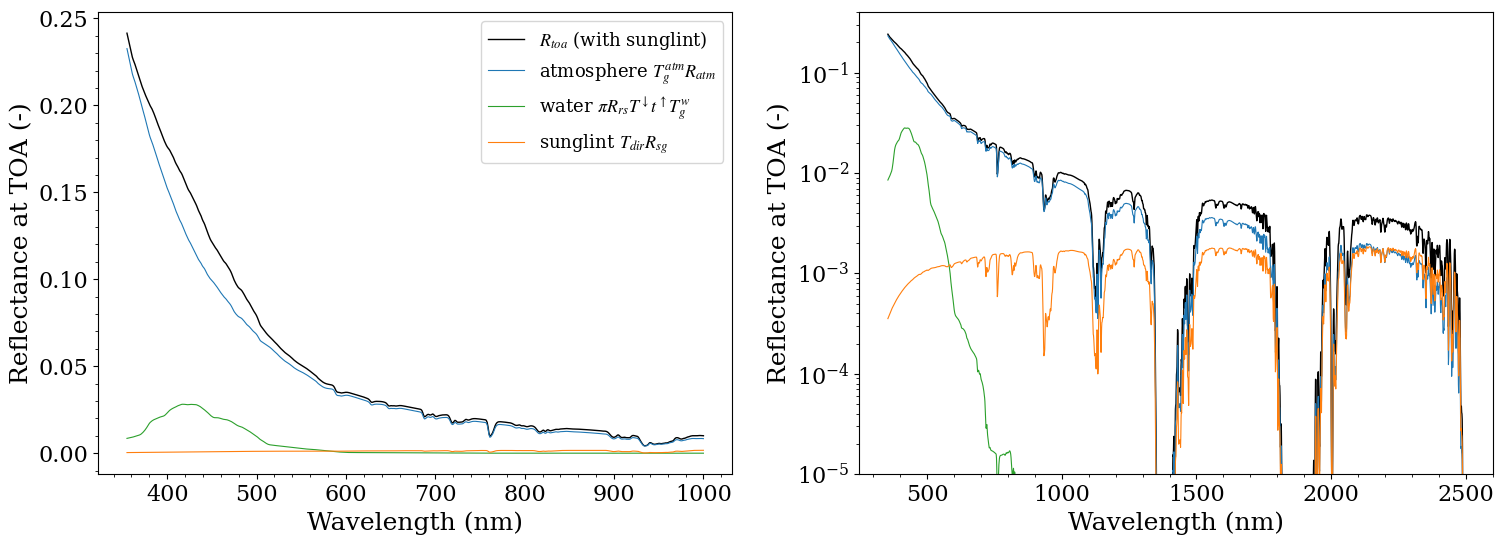

In [6]:
def plot_terms(db, ax, wl_range=slice(355, 2495), log=False):
    d = smooth(db[['Rtoa_sg', 'Ratm', 'Rw_toa', 'Rsg_toa']]).sel(wl=wl_range)
    d.Rtoa_sg.plot(x='wl', ax=ax, color='k', lw=1., label=r'$R_{toa}$ (with sunglint)')
    d.Ratm.plot(x='wl', ax=ax, color='tab:blue', lw=0.8, label=r'atmosphere $T_g^{atm} R_{atm}$')
    d.Rw_toa.plot(x='wl', ax=ax, color='tab:green', lw=0.8, label=r'water $\pi R_{rs} T^{\downarrow} t^{\uparrow} T_g^{w}$')
    d.Rsg_toa.plot(x='wl', ax=ax, color='tab:orange', lw=0.8, label=r'sunglint $T_{dir} R_{sg}$')
    if log:
        ax.set_yscale('log')
        ax.set_ylim(1e-5, 0.4)
    ax.set_xlabel('Wavelength (nm)')
    ax.set_ylabel('Reflectance at TOA (-)')
    ax.set_title('')
    ax.minorticks_on()


fig, axs = plt.subplots(1, 2, figsize=(18, 6))
plot_terms(db, axs[0], slice(355, 1000))
plot_terms(db, axs[1], log=True)
axs[0].legend(fontsize=13)
plt.show()

The TOA radiance is $L_{toa} = R_{toa}\, E_0/\pi$, with $E_0 = \mu_0\, d^2\, F_0$ the plane irradiance at
the TOA (output `E0`, mW m$^{-2}$ nm$^{-1}$); `Ed` is the downwelling irradiance at the surface.

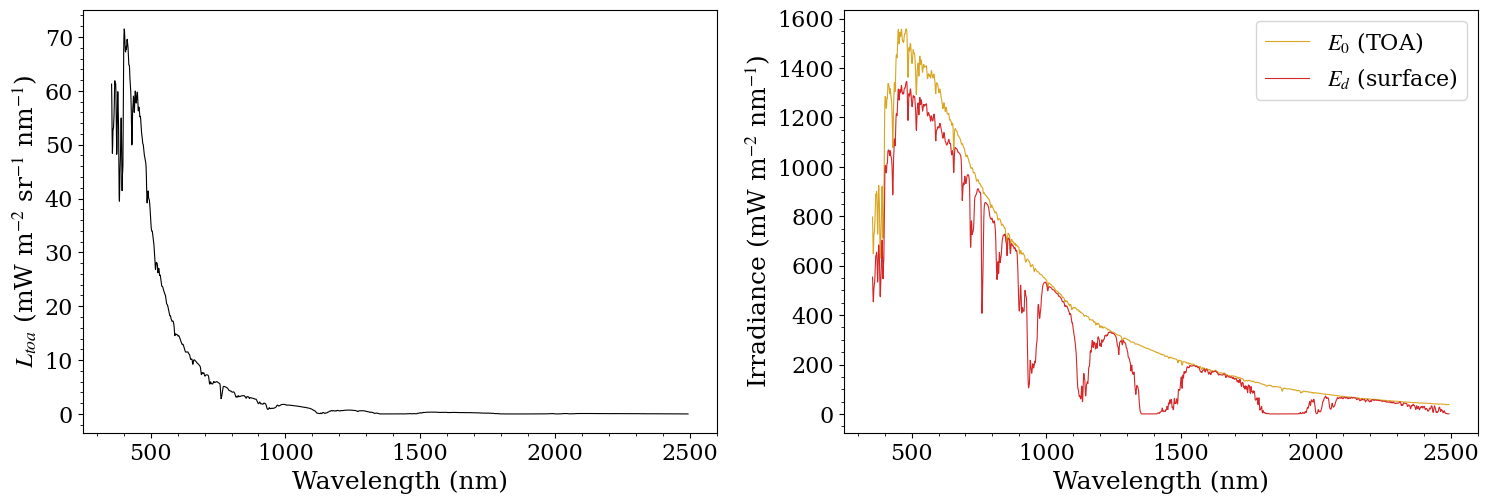

In [7]:
Ltoa = db.Rtoa_sg * db.E0 / np.pi
fig, axs = plt.subplots(1, 2, figsize=(18, 5.5))
smooth(Ltoa).plot(x='wl', ax=axs[0], color='k', lw=0.8)
axs[0].set_ylabel(r'$L_{toa}$ (mW m$^{-2}$ sr$^{-1}$ nm$^{-1}$)')
smooth(db.E0).plot(x='wl', ax=axs[1], color='goldenrod', lw=0.8, label=r'$E_0$ (TOA)')
smooth(db.Ed).plot(x='wl', ax=axs[1], color='tab:red', lw=0.8, label=r'$E_d$ (surface)')
axs[1].set_ylabel(r'Irradiance (mW m$^{-2}$ nm$^{-1}$)')
axs[1].legend()
for ax in axs:
    ax.set_xlabel('Wavelength (nm)')
    ax.set_title('')
    ax.minorticks_on()
plt.show()

## Atmosphere

### Aerosol optical thickness

A list of values of a setting gives one scenario per value in a single run. The path reflectance increases
with the aerosol load at all wavelengths; the water term decreases with the diffuse transmittance.

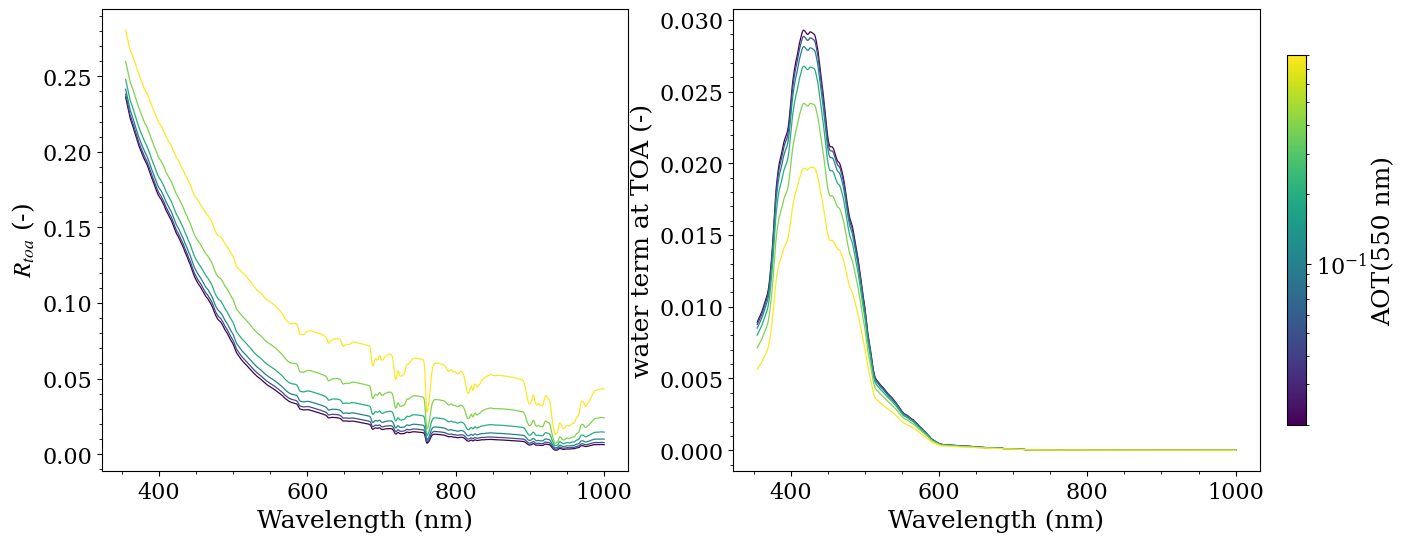

In [8]:
aots = [0.02, 0.05, 0.1, 0.2, 0.4, 0.8]
db_aot = simulate(settings, aot550=aots)

cmap = plt.cm.viridis
norm = mpl.colors.LogNorm(vmin=0.02, vmax=0.8)
fig, axs = plt.subplots(1, 2, figsize=(18, 6))
d = smooth(db_aot[['Rtoa_sg', 'Rw_toa']]).sel(wl=slice(355, 1000))
for it, aot in enumerate(aots):
    d.Rtoa_sg.isel(time=it).plot(x='wl', ax=axs[0], color=cmap(norm(aot)), lw=0.9)
    d.Rw_toa.isel(time=it).plot(x='wl', ax=axs[1], color=cmap(norm(aot)), lw=0.9)
axs[0].set_ylabel(r'$R_{toa}$ (-)')
axs[1].set_ylabel(r'water term at TOA (-)')
for ax in axs:
    ax.set_xlabel('Wavelength (nm)')
    ax.set_title('')
    ax.minorticks_on()
cb = fig.colorbar(mpl.cm.ScalarMappable(norm=norm, cmap=cmap), ax=axs, shrink=0.8, pad=0.02)
cb.set_label('AOT(550 nm)')
plt.show()

### Aerosol models

The aerosol is a mixture of the OPAC models of `config.yml` (`settings: aerosol_models`), with the
proportions `aerosol_combination` (Eq. {eq}`mixture`, {ref}`methods-aerosol`). For the same AOT at
550 nm, the models differ by their spectral dependence (Angström exponent) and their phase function: fine
particles (continental, urban) give more signal in the blue, coarse ones (maritime, desert) in the
near and shortwave infrared. The proportions can also be retrieved from the AERONET spectral AOT with
{py:class}`~radcalnet_oc.kernel.Aerosol`.

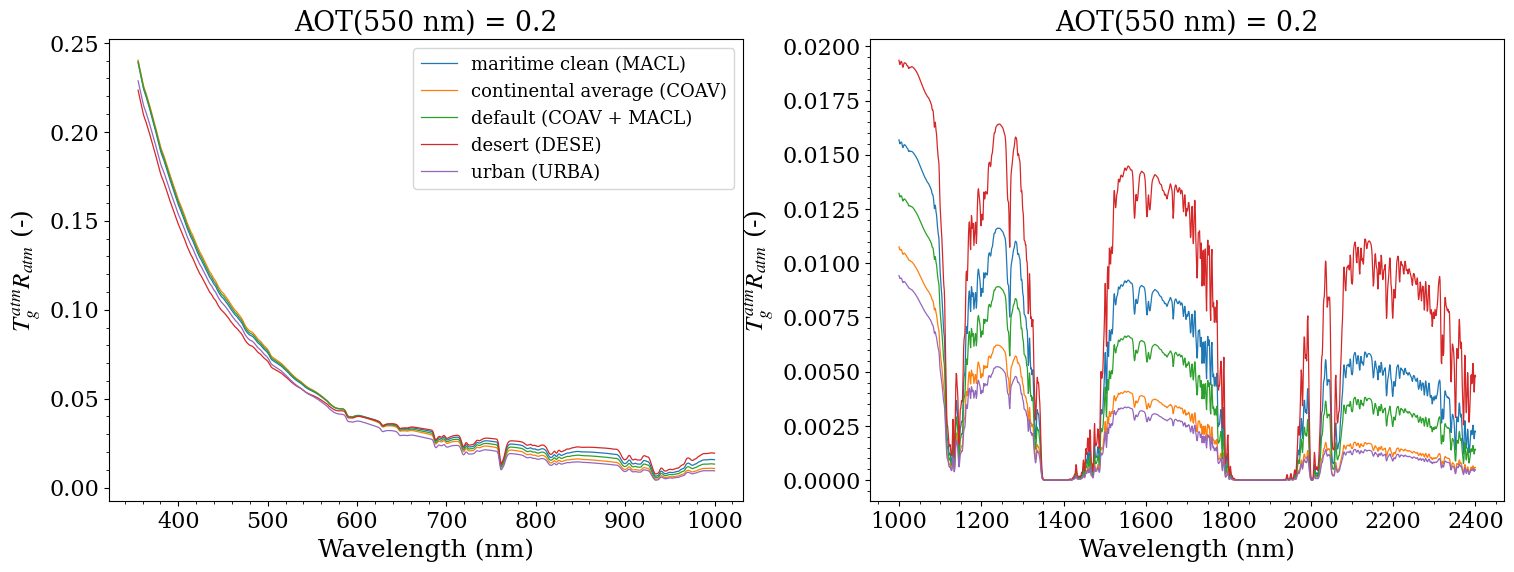

In [9]:
combinations = {'maritime clean (MACL)': [0, 0, 0, 1, 0, 0],
                'continental average (COAV)': [0, 1, 0, 0, 0, 0],
                'default (COAV + MACL)': [0, 0.5, 0, 0.5, 0, 0],
                'desert (DESE)': [0, 0, 1, 0, 0, 0],
                'urban (URBA)': [0, 0, 0, 0, 1, 0]}

fig, axs = plt.subplots(1, 2, figsize=(18, 6))
for (name, comb), color in zip(combinations.items(), plt.cm.tab10.colors):
    Ratm = smooth(simulate({**settings, 'aerosol_combination': comb, 'aot550': 0.2}).Ratm)
    Ratm.sel(wl=slice(355, 1000)).plot(x='wl', ax=axs[0], color=color, lw=0.9, label=name)
    Ratm.sel(wl=slice(1000, 2400)).plot(x='wl', ax=axs[1], color=color, lw=0.9)
axs[0].legend(fontsize=13)
for ax in axs:
    ax.set_xlabel('Wavelength (nm)')
    ax.set_ylabel(r'$T_g^{atm} R_{atm}$ (-)')
    ax.set_title('AOT(550 nm) = 0.2')
    ax.minorticks_on()
plt.show()

### Gaseous absorption and its coupling with the scattering

The water vapour column changes the depth of the H$_2$O bands. The gaseous transmittance of each term
depends on the option `gas_coupling` (see {ref}`methods-gas-coupling` and the research tutorial
{doc}`research/radcalnet_oc_gaseous_coupling`):

- `'path_length'` (default): photon path-length model, fitted on radiative transfer simulations of the
  absorption coupled with the scattering;
- `'effective_air_mass'`: effective air masses per absorption window;
- `'decoupled'`: all the terms see the air mass of the direct beam (versions before 1.1). The light
  scattered in the atmosphere crosses less absorber than the direct beam, so this option overestimates
  the depth of the bands of the path reflectance.

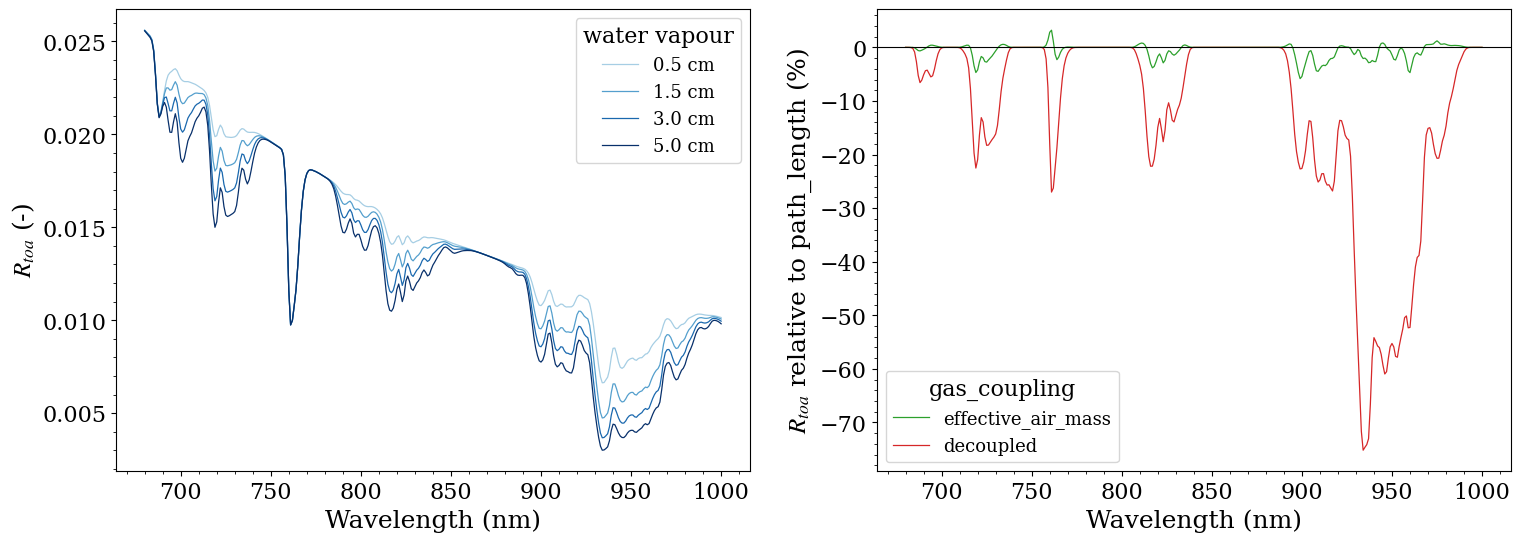

In [10]:
tcwvs = [0.5, 1.5, 3., 5.]  # cm
db_wv = simulate(settings, tcwv=[10 * w for w in tcwvs])

fig, axs = plt.subplots(1, 2, figsize=(18, 6))
Rtoa_wv = smooth(db_wv.Rtoa_sg).sel(wl=slice(680, 1000))
for it, (w, color) in enumerate(zip(tcwvs, plt.cm.Blues(np.linspace(0.35, 1, len(tcwvs))))):
    Rtoa_wv.isel(time=it).plot(x='wl', ax=axs[0], color=color, lw=0.9, label=f'{w} cm')
axs[0].legend(title='water vapour', fontsize=13)
axs[0].set_ylabel(r'$R_{toa}$ (-)')

Rtoa_cp = {c: smooth(simulate(settings, options={**options, 'gas_coupling': c}).Rtoa_sg).sel(wl=slice(680, 1000))
           for c in ['path_length', 'effective_air_mass', 'decoupled']}
for coupling, color in zip(['effective_air_mass', 'decoupled'], ['tab:green', 'tab:red']):
    (100 * (Rtoa_cp[coupling] / Rtoa_cp['path_length'] - 1)).plot(x='wl', ax=axs[1], color=color, lw=0.9,
                                                                   label=coupling)
axs[1].axhline(0, color='k', lw=0.8)
axs[1].legend(title='gas_coupling', fontsize=13)
axs[1].set_ylabel(r'$R_{toa}$ relative to path_length (%)')
for ax in axs:
    ax.set_xlabel('Wavelength (nm)')
    ax.set_title('')
    ax.minorticks_on()
plt.show()

The O$_2$ bands are computed line by line by default (`o2_model='lbl'`), closer to the absorption of the
radiative transfer simulations of the coupling fit and needed at sub-nanometre resolution (e.g. FLEX).
REPTRAN (`'reptran'`, as before version 1.1) gives a deeper O$_2$-A band. The figure is at the full
resolution of the simulation (0.1 nm).

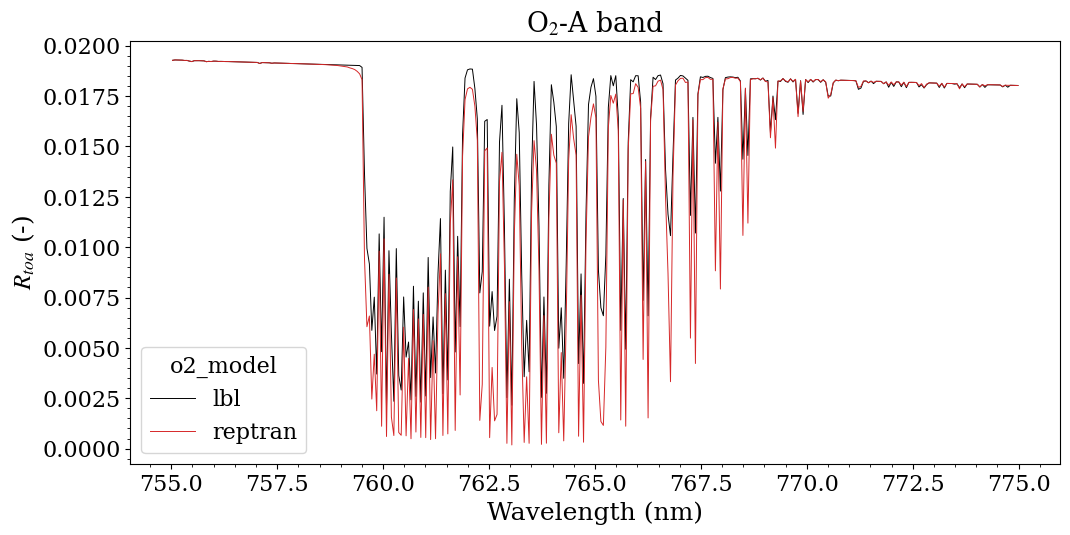

In [11]:
fig, ax = plt.subplots(figsize=(12, 5.5))
for o2_model, color in zip(['lbl', 'reptran'], ['k', 'tab:red']):
    d = simulate(settings, options={**options, 'o2_model': o2_model})
    d.Rtoa_sg.sel(wl=slice(755, 775)).plot(x='wl', ax=ax, color=color, lw=0.7, label=o2_model)
ax.legend(title='o2_model')
ax.set_xlabel('Wavelength (nm)')
ax.set_ylabel(r'$R_{toa}$ (-)')
ax.set_title('O$_2$-A band')
ax.minorticks_on()
plt.show()

## Sea-surface roughness

The wind speed sets the roughness of the sea surface: the slope distribution of the wave facets that
reflect the skylight (in the look-up tables, interpolated between their wind nodes 0.5-16 m s$^{-1}$) and
the direct sunlight (sunglint).

Away from the specular direction (azimuth 90°), the wind changes the skylight reflection and the far
tail of the glint. Close to the specular direction (azimuth 0°, viewing zenith angle 30°: glint angle
of 10°), the sunglint dominates the signal; a rougher sea spreads the glint and lowers its peak.

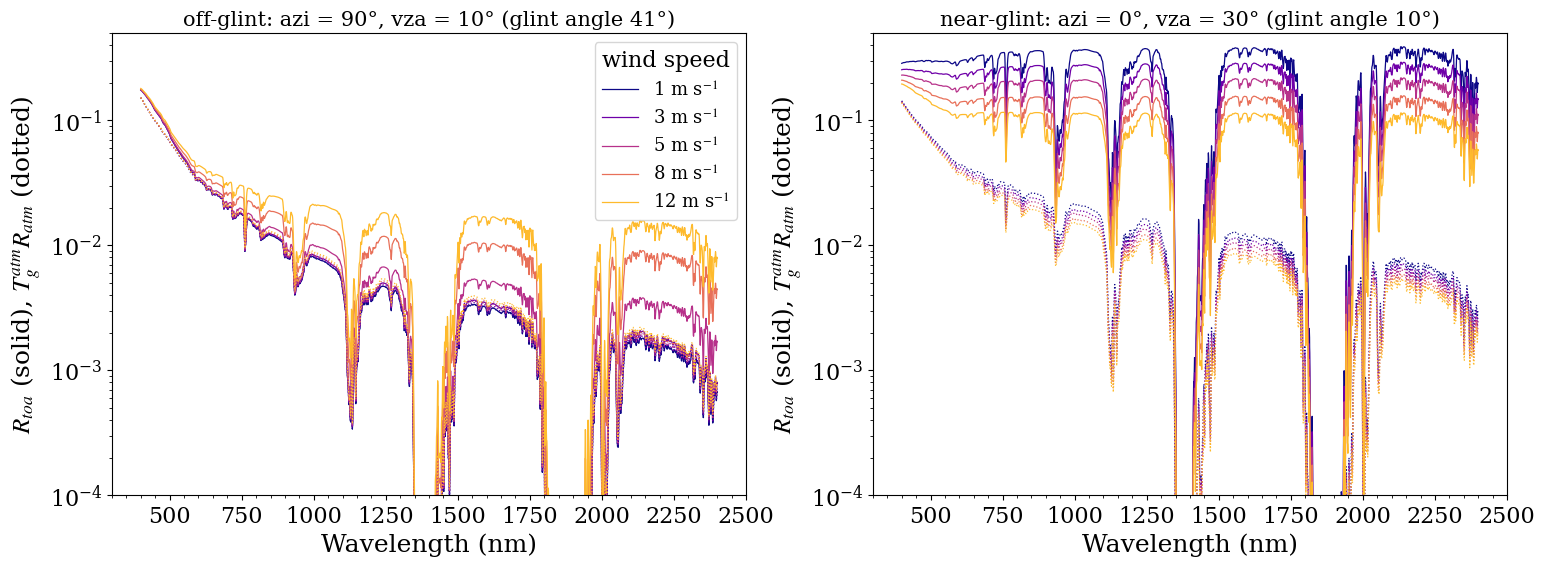

,wind (m s-1),R_sg at the surface,sunglint / R_toa at 865 nm
0,1,0.4158,0.9282
1,3,0.3111,0.9135
2,5,0.2319,0.8940
3,8,0.1656,0.8675
4,12,0.1194,0.8341


In [12]:
winds = [1, 3, 5, 8, 12]
colors = plt.cm.plasma(np.linspace(0, 0.85, len(winds)))
geometries = {'off-glint: azi = 90°, vza = 10°': dict(azi=90., vza=10.),
              'near-glint: azi = 0°, vza = 30°': dict(azi=0., vza=30.)}

fig, axs = plt.subplots(1, 2, figsize=(18, 6))
for ax, (title, geom) in zip(axs, geometries.items()):
    d = simulate({**settings, **geom}, wind=winds)
    ds = smooth(d[['Rtoa_sg', 'Ratm']]).sel(wl=slice(400, 2400))
    for it, (w, color) in enumerate(zip(winds, colors)):
        ds.Rtoa_sg.isel(time=it).plot(x='wl', ax=ax, color=color, lw=0.9, label=f'{w} m s$^{{-1}}$')
        ds.Ratm.isel(time=it).plot(x='wl', ax=ax, color=color, lw=0.9, ls=':')
    ax.set_yscale('log')
    ax.set_ylim(1e-4, 0.5)
    ax.set_title(f"{title} (glint angle {float(d.glint_angle[0]):.0f}°)", fontsize=15)
    ax.set_xlabel('Wavelength (nm)')
    ax.set_ylabel(r'$R_{toa}$ (solid), $T_g^{atm} R_{atm}$ (dotted)')
    ax.minorticks_on()
axs[0].legend(title='wind speed', fontsize=13)
plt.show()

d = simulate({**settings, **geometries['near-glint: azi = 0°, vza = 30°']}, wind=winds)
pd.DataFrame({'wind (m s-1)': winds, 'R_sg at the surface': d.Rsg.values,
              'sunglint / R_toa at 865 nm': (d.Rsg_toa / d.Rtoa_sg).sel(wl=865, method='nearest').values}).round(4)

## Water reflectance

The water term follows the remote-sensing reflectance: here the clear and turbid water templates of the
package and black water ($R_{rs} = 0$, the signal of the atmosphere and of the surface alone).

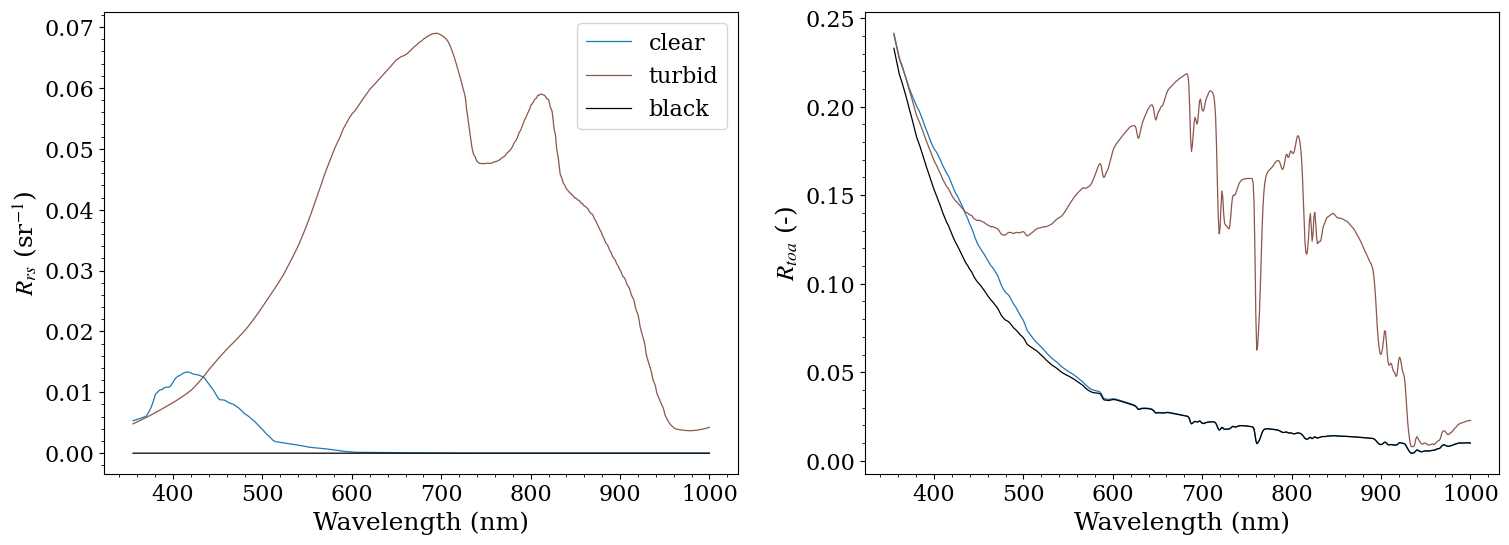

In [13]:
waters = ['clear', 'turbid', 'black']
db_w = simulate(settings, water=waters)

fig, axs = plt.subplots(1, 2, figsize=(18, 6))
Rtoa_w = smooth(db_w.Rtoa_sg).sel(wl=slice(355, 1000))
for it, (w, color) in enumerate(zip(waters, ['tab:blue', 'tab:brown', 'k'])):
    db_w.Rrs.isel(time=it).sel(wl=slice(355, 1000)).plot(x='wl', ax=axs[0], color=color, lw=0.9, label=w)
    Rtoa_w.isel(time=it).plot(x='wl', ax=axs[1], color=color, lw=0.9, label=w)
axs[0].set_ylabel(r'$R_{rs}$ (sr$^{-1}$)')
axs[1].set_ylabel(r'$R_{toa}$ (-)')
axs[0].legend()
for ax in axs:
    ax.set_xlabel('Wavelength (nm)')
    ax.set_title('')
    ax.minorticks_on()
plt.show()

Beyond the range of the input (1150 nm for the templates), $R_{rs}$ is extended with a semi-analytical
model of pure water whose particulate backscattering is fitted on the near-infrared end of the input
(`rrs_extension='pure_water'`, default), or set to zero (`'zero'`, versions before 1.1). The difference
matters for turbid waters in the shortwave infrared.

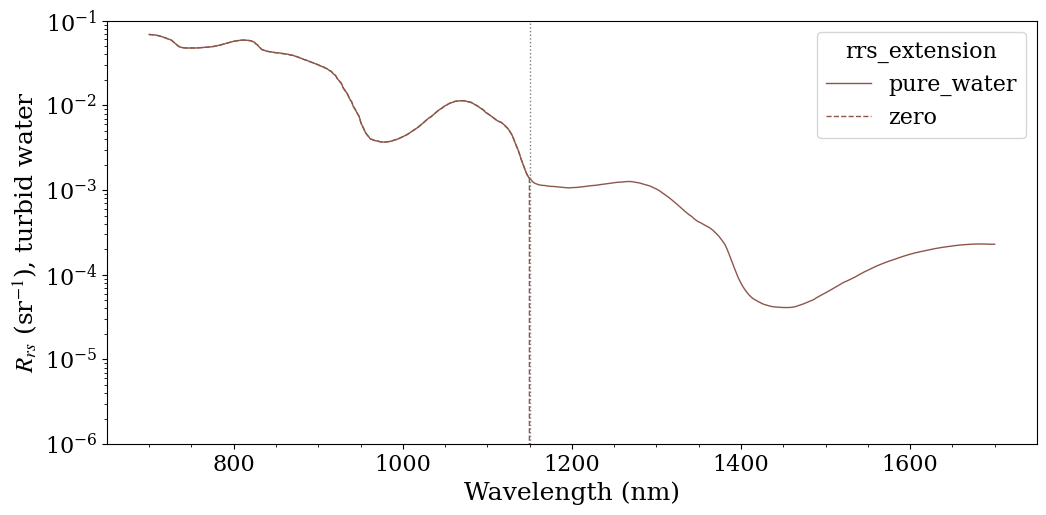

In [14]:
fig, ax = plt.subplots(figsize=(12, 5.5))
for ext, ls in zip(['pure_water', 'zero'], ['-', '--']):
    d = simulate({**settings, 'water': 'turbid'}, options={**options, 'rrs_extension': ext})
    d.Rrs.sel(wl=slice(700, 1700)).plot(x='wl', ax=ax, color='tab:brown', ls=ls, lw=1, label=ext)
ax.axvline(1150, color='grey', lw=1, ls=':')
ax.set_yscale('log')
ax.set_ylim(1e-6, 0.1)
ax.legend(title='rrs_extension')
ax.set_xlabel('Wavelength (nm)')
ax.set_ylabel(r'$R_{rs}$ (sr$^{-1}$), turbid water')
ax.set_title('')
ax.minorticks_on()
plt.show()

## Satellite bands

The hyperspectral simulation is convolved with the spectral responses of the sensor
({ref}`spectral_convolution`): Gaussian (or super-Gaussian) responses from the central wavelengths and
widths of the bands, as below for bands close to those of Sentinel-2/MSI, or the tabulated responses of
the instrument with {py:meth}`Spectral.from_srf <radcalnet_oc.lut.Spectral.from_srf>`.

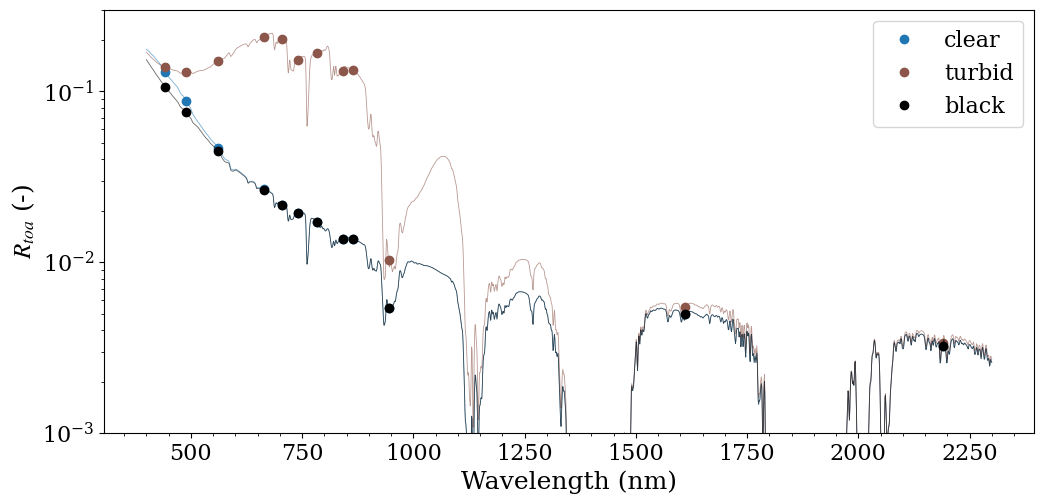

In [15]:
bands = pd.DataFrame({'band': ['B1', 'B2', 'B3', 'B4', 'B5', 'B6', 'B7', 'B8', 'B8A', 'B9', 'B11', 'B12'],
                      'wl': [443, 490, 560, 665, 705, 740, 783, 842, 865, 945, 1610, 2190],
                      'fwhm': [20, 65, 35, 30, 15, 15, 20, 115, 20, 20, 90, 180]})
spectral = radoc.Spectral(central_wl=bands.wl.values.astype(float), fwhm=bands.fwhm.values.astype(float))
Rtoa_bands = spectral.convolve2(db_w.Rtoa_sg.rename('Rtoa'))
Rtoa_bands = Rtoa_bands['Rtoa'] if isinstance(Rtoa_bands, xr.Dataset) else Rtoa_bands

fig, ax = plt.subplots(figsize=(12, 5.5))
for it, (w, color) in enumerate(zip(waters, ['tab:blue', 'tab:brown', 'k'])):
    smooth(db_w.Rtoa_sg.isel(time=it)).sel(wl=slice(400, 2300)).plot(x='wl', ax=ax, color=color, lw=0.6, alpha=0.6)
    ax.plot(bands.wl, Rtoa_bands.isel(time=it).squeeze(), 'o', color=color, label=w)
ax.set_yscale('log')
ax.set_ylim(1e-3, 0.3)
ax.legend()
ax.set_xlabel('Wavelength (nm)')
ax.set_ylabel(r'$R_{toa}$ (-)')
ax.set_title('')
ax.minorticks_on()
plt.show()

## Save the simulation

The dataset is written in NetCDF with its settings as global attributes:

```python
db.to_netcdf('radcalnet_oc_simulation.nc')
```

To simulate the measurements of an AERONET-OC site (its $R_{rs}$, AOT and the atmospheric columns of each
measurement), see the tutorial {doc}`radcalnet_oc_aeronet_oc_toa`; the sunglint is studied in detail in
{doc}`research/radcalnet_oc_sunglint`.